# 04 · Model diagnostics

Two checks on the rolling-origin backtest (`negprice/backtest.py`), both on the same folds as `make backtest`:

1. **AEMO recalibrated vs drift in AEMO's own forecast.** Why its mean prediction in the test months differs from the training-window share of negatives.
2. **Feature importance of `xgb_v1`**, per region.

Neither check uses test-month labels to choose anything.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

from negprice.backtest import XGBoostV1, make_folds, scorable, year_label
from negprice.config import PROCESSED_DATA_DIR, REGIONS

features = pd.read_parquet(PROCESSED_DATA_DIR / "features.parquet")
preds = pd.read_parquet(PROCESSED_DATA_DIR / "backtest_predictions.parquet")
folds = make_folds()
print(f"{len(folds)} folds: {folds[0].test_start:%b %Y} - {folds[-1].test_end:%b %Y}")

36 folds: Oct 2023 - Sep 2026


In [2]:
def window_and_test(data: pd.DataFrame, fold) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Rows AEMO recalibrated is fitted on (full training window, AEMO forecast present)
    and rows it is scored on (test month, scorable)."""
    day = data["DAY"]
    window = data[(day >= fold.train_start) & (day <= fold.train_end) & data["pd_rrp"].notna()]
    test = data[(day >= fold.test_start) & (day <= fold.test_end)]
    return window, test[scorable(test)]


def by_year(rows: list[dict], cols: list[str]) -> pd.DataFrame:
    """Average the per-fold values over the folds of each Oct-Sep year, in %."""
    return pd.DataFrame(rows).groupby(["REGIONID", "test_year"])[cols].mean().mul(100).round(1)

## 1. AEMO recalibrated vs drift in AEMO's forecast

**Why:** a logistic regression with an intercept matches the share of negatives on its own training data. So in each fold, AEMO recalibrated's mean prediction over the training window equals the window share. If its mean prediction in the test month differs from that, the inputs (AEMO's forecast prices) must differ between window and test month.

### A. The gap: window share vs mean prediction vs actual share

In [3]:
rows = []
for region in REGIONS:
    data = features[features["REGIONID"] == region]
    p = preds[(preds["REGIONID"] == region) & (preds["model"] == "aemo_recal") & preds["scored"]]
    for fold in folds:
        window, _ = window_and_test(data, fold)
        t = p[p["fold"] == fold.number]
        rows.append({
            "REGIONID": region,
            "test_year": year_label(pd.Series([fold.test_start])).iloc[0],
            "window_share": window["is_neg"].mean(),
            "test_mean_prob": t["prob"].mean(),
            "test_share": t["is_neg"].mean(),
        })

gap = by_year(rows, ["window_share", "test_mean_prob", "test_share"])
gap

window_share  test_mean_prob  test_share
REGIONID test_year                                          
NSW1     2023-24             4.7             5.5         7.1
         2024-25             7.4             7.5        10.3
         2025-26            10.0             9.5         8.8
SA1      2023-24            23.2            26.9        25.2
         2024-25            26.3            26.7        28.2
         2025-26            28.5            25.9        29.0
VIC1     2023-24            19.7            23.1        21.6
         2024-25            22.8            23.4        22.6
         2025-26            23.8            22.7        25.9


### B. How often AEMO forecast a negative price (`pd_rrp` < 0), window vs test month

In [4]:
rows = []
for region in REGIONS:
    data = features[features["REGIONID"] == region]
    for fold in folds:
        window, test = window_and_test(data, fold)
        rows.append({
            "REGIONID": region,
            "test_year": year_label(pd.Series([fold.test_start])).iloc[0],
            "window": (window["pd_rrp"] < 0).mean(),
            "test": (test["pd_rrp"] < 0).mean(),
        })

forecast_share = by_year(rows, ["window", "test"])
forecast_share

window  test
REGIONID test_year              
NSW1     2023-24       8.2  10.4
         2024-25      10.9  13.4
         2025-26      13.9  16.0
SA1      2023-24      19.5  23.9
         2024-25      24.0  28.1
         2025-26      28.1  28.7
VIC1     2023-24      16.2  19.9
         2024-25      20.5  23.8
         2025-26      24.6  27.7

**Result:** There is a gap between the forecast prices in training and test windows. AEMO forecast forecast more negative shares in recent years. 

### C. How negative AEMO's negative forecasts were

Share of all half-hours whose AEMO forecast falls in each price band ($/MWh). The recalibration curve uses the price clipped to [−$50, +$50], so depth inside that range changes its output.

In [5]:
BANDS = [-np.inf, -50, -20, -10, -1, 0]
LABELS = ["< -50", "-50 to -20", "-20 to -10", "-10 to -1", "-1 to 0"]


def band_shares(rows: pd.DataFrame) -> dict:
    band = pd.cut(rows["pd_rrp"], BANDS, right=False, labels=LABELS)
    return (band.value_counts() / len(rows)).to_dict()


out = []
for region in REGIONS:
    data = features[features["REGIONID"] == region]
    for fold in folds:
        window, test = window_and_test(data, fold)
        ty = year_label(pd.Series([fold.test_start])).iloc[0]
        out.append({"REGIONID": region, "test_year": ty, "set": "window", **band_shares(window)})
        out.append({"REGIONID": region, "test_year": ty, "set": "test", **band_shares(test)})

depth = pd.DataFrame(out).groupby(["REGIONID", "test_year", "set"])[LABELS].mean().mul(100).round(1)
depth

< -50  -50 to -20  -20 to -10  -10 to -1  -1 to 0
REGIONID test_year set                                                      
NSW1     2023-24   test      2.6         6.1         1.2        0.5      0.0
                   window    3.2         3.8         0.6        0.4      0.2
         2024-25   test      1.4         8.7         2.5        0.7      0.1
                   window    2.8         6.5         1.0        0.5      0.1
         2025-26   test      0.9         4.8         2.9        6.9      0.5
                   window    1.7         7.6         2.4        2.0      0.1
SA1      2023-24   test      8.8        12.4         1.8        0.8      0.1
                   window    9.4         8.1         1.2        0.7      0.1
         2024-25   test      7.3        12.3         6.2        2.2      0.2
                   window    9.3        11.6         1.9        1.0      0.1
         2025-26   test      6.0         4.4         5.3       11.2      1.8
                   window    7.7        11.2         5.1        3.7      0.4
VIC1     2023-24   test      7.3         9.1         2.3        1.1      0.1
                   window    6.8         6.7         1.8        0.7      0.2
         2024-25   test      6.0        10.0         5.3        2.3      0.2
                   window    7.8         9.0         2.5        1.0      0.1
         2025-26   test      5.2         4.9         4.2       11.0      2.4
                   window    6.3         9.3         4.4        4.0      0.5

**Result:** The amount of prices within the -10 to -1 blocks for SA and NSW has increased.

## 2. Feature importance of `xgb_v1`

**Why:** shows which inputs the model actually relies on in each region.

**Method:** refit `xgb_v1` exactly as in the backtest (same settings and full training window per fold) and take each feature's share of **total gain** (sum of loss reduction over all splits that use it), averaged over the 36 folds. No test-month data involved.

**Caveat:** gain favours continuous features with many possible split points, and correlated features (e.g. `pd_rrp` and the neighbour prices) share credit. It is not the drop in Brier from removing a feature.

**Expected:** ranking NEM hour > `pd_rrp` > demand forecast > PV forecast > wind forecast > season > type of day, with the D-2 price adding little. NSW leans almost only on `pd_rrp`.

In [6]:
model = XGBoostV1()
shares = []
for region in REGIONS:
    data = features[features["REGIONID"] == region]
    for fold in folds:
        train = data[(data["DAY"] >= fold.train_start) & (data["DAY"] <= fold.train_end)]
        xgb, cols = model.fit(train, model.candidates[0])
        gain = pd.Series(xgb.get_booster().get_score(importance_type="total_gain"))
        gain = gain.reindex(cols, fill_value=0.0)
        shares.append((gain / gain.sum()).rename((region, fold.number)))

importance = pd.concat(shares, axis=1).T.groupby(level=0).mean().T.mul(100).round(1)
importance = importance[REGIONS].loc[lambda d: d.mean(axis=1).sort_values(ascending=False).index]
importance

,SA1,VIC1,NSW1
pd_rrp,48.4,47.2,42.1
pd_rrp_vic1,14.4,NaN,3.8
pd_rrp_sa1,NaN,14.9,1.9
pd_totaldemand,2.1,3.7,8.4
pd_uigf,4.0,4.0,6.2
pd_ss_solar_uigf,2.4,2.7,3.5
pvf_mw,2.3,1.8,3.9
pd_ss_wind_uigf,1.8,1.8,4.2
silo_radiation_d2,2.8,2.3,2.7
silo_max_temp_d2,2.5,2.3,2.7


**Result:** pd_rrp (AEMO forecast) is the most important feature across all regions. The grid connection between SA and VIC plays an important role too (pd_rrp_vic1, pd_rrp_sa1). NSW is less dependent on those, but pd_totaldemand and pd_uigf are significant. 

## 3. Training vs validation Brier by number of trees

**Why:** shows whether `xgb_v1` overfits. Training Brier always falls as trees are added; if validation Brier bottoms out and then rises, the model overfits past that point. If it is still falling at 500 trees, it does not.

**Method:** in each fold, fit `xgb_v1` on the inner training part (first 21 months, as in the backtest's candidate step). Score Brier on that inner part and on the 3 validation months, using the first 50, 100, …, 500 trees of the same fit. Average over the 36 folds per region. No test-month data involved.

**Expected:** validation Brier bottoms out around 100 trees; largest training–validation gap in NSW.

In [7]:
from xgboost import XGBClassifier

from negprice.backtest import XGB_V1_PARAMS, brier

TREES = range(50, XGB_V1_PARAMS["n_estimators"] + 1, 50)

rows = []
for region in REGIONS:
    data = features[features["REGIONID"] == region]
    cols = XGBoostV1.feature_columns(region)
    for fold in folds:
        day = data["DAY"]
        inner = data[(day >= fold.train_start) & (day <= fold.inner_end)]
        val = data[(day >= fold.val_start) & (day <= fold.train_end)]
        val = val[scorable(val)]
        xgb = XGBClassifier(**XGB_V1_PARAMS).fit(inner[cols], inner["is_neg"])
        for k in TREES:
            rows.append({
                "REGIONID": region,
                "fold": fold.number,
                "trees": k,
                "train": brier(inner["is_neg"], xgb.predict_proba(inner[cols], iteration_range=(0, k))[:, 1]),
                "val": brier(val["is_neg"], xgb.predict_proba(val[cols], iteration_range=(0, k))[:, 1]),
            })

curve = pd.DataFrame(rows).groupby(["REGIONID", "trees"])[["train", "val"]].mean()
curve["gap"] = curve["val"] - curve["train"]
curve.unstack("REGIONID").round(4)

train                     val                     gap          \
REGIONID    NSW1     SA1    VIC1    NSW1     SA1    VIC1    NSW1     SA1   
trees                                                                      
50        0.0221  0.0508  0.0455  0.0410  0.0673  0.0631  0.0189  0.0165   
100       0.0184  0.0425  0.0382  0.0405  0.0659  0.0620  0.0222  0.0235   
150       0.0153  0.0366  0.0326  0.0409  0.0661  0.0625  0.0257  0.0295   
200       0.0127  0.0320  0.0281  0.0414  0.0665  0.0631  0.0287  0.0345   
250       0.0106  0.0281  0.0247  0.0419  0.0670  0.0636  0.0313  0.0388   
300       0.0089  0.0249  0.0218  0.0423  0.0673  0.0641  0.0334  0.0424   
350       0.0075  0.0222  0.0194  0.0427  0.0677  0.0644  0.0352  0.0455   
400       0.0064  0.0199  0.0172  0.0430  0.0680  0.0648  0.0366  0.0481   
450       0.0054  0.0178  0.0154  0.0433  0.0684  0.0652  0.0379  0.0506   
500       0.0045  0.0160  0.0137  0.0436  0.0687  0.0656  0.0390  0.0528   

                  
REGIONID    VIC1  
trees             
50        0.0176  
100       0.0238  
150       0.0299  
200       0.0350  
250       0.0389  
300       0.0422  
350       0.0451  
400       0.0476  
450       0.0498  
500       0.0519

In [8]:
best = pd.DataFrame(rows).loc[lambda d: d.groupby(["REGIONID", "fold"])["val"].idxmin()]
best.groupby("REGIONID")["trees"].describe()[["mean", "25%", "50%", "75%"]]

,mean,25%,50%,75%
REGIONID,,,,
NSW1,125.000000,50.0,100.0,150.0
SA1,120.833333,100.0,100.0,150.0
VIC1,115.277778,50.0,100.0,150.0


## 4. Reliability of xgb_v2 on the validation months

**Why:** a probability forecast should mean what it says: of the half-hours given about 30%, about 30% should turn out negative. This decides whether a calibration step is needed, so it uses validation months only, never test months.

**Method:** in each fold, refit the setting `xgb_v2` chose (from `selections.csv`) on the 21-month inner part and predict the 3 validation months. Group those half-hours by predicted probability (10 bands of 10 points). Per band: mean predicted probability vs share actually negative. `diff_pts` > 0 means the model over-predicts in that band.

**Expected:** over-prediction mostly in the 0–10% band.

In [9]:
import ast

from xgboost import XGBClassifier
import matplotlib.pyplot as plt

from negprice.config import REPORTS_DIR

chosen = pd.read_csv(REPORTS_DIR / "backtest" / "selections.csv")
chosen = chosen[chosen["model"] == "xgb_v2"].set_index(["REGIONID", "fold"])["params"]

parts = []
for region in REGIONS:
    data = features[features["REGIONID"] == region]
    cols = XGBoostV1.feature_columns(region)
    for fold in folds:
        params = ast.literal_eval(chosen[(region, fold.number)])
        day = data["DAY"]
        inner = data[(day >= fold.train_start) & (day <= fold.inner_end)]
        val = data[(day >= fold.val_start) & (day <= fold.train_end)]
        val = val[scorable(val)]
        xgb = XGBClassifier(**params).fit(inner[cols], inner["is_neg"])
        parts.append(pd.DataFrame({
            "REGIONID": region,
            "prob": xgb.predict_proba(val[cols])[:, 1],
            "is_neg": val["is_neg"].to_numpy(),
        }))

v = pd.concat(parts, ignore_index=True)
v["band"] = pd.cut(v["prob"], np.linspace(0, 1, 11), include_lowest=True)

reliability = v.groupby(["REGIONID", "band"], observed=True).agg(
    n=("prob", "size"),
    mean_prob=("prob", "mean"),
    share_neg=("is_neg", "mean"),
)
reliability["diff_pts"] = (reliability["mean_prob"] - reliability["share_neg"]) * 100



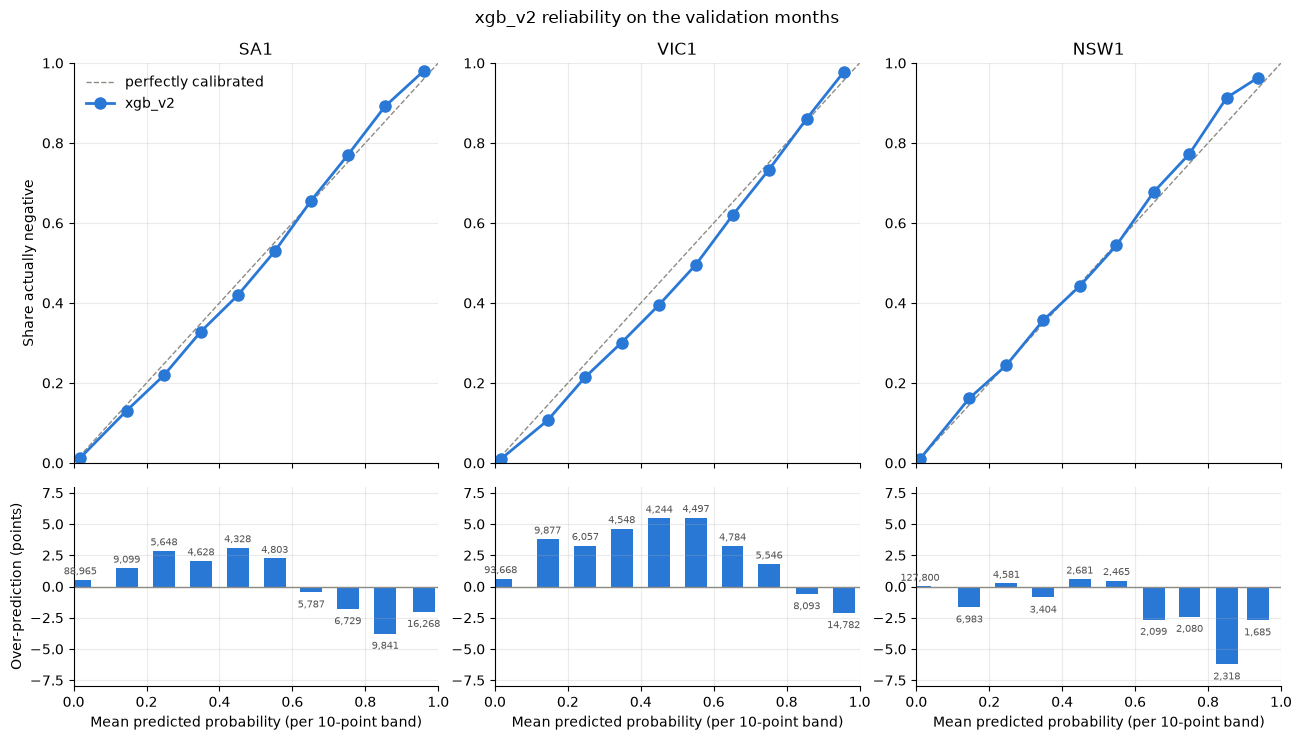

In [10]:
import matplotlib.pyplot as plt

BLUE, GREY = "#2a78d6", "#8c8b85"
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
for i, region in enumerate(REGIONS):
    r = reliability.loc[region]
    top, bottom = axes[0, i], axes[1, i]

    top.plot([0, 1], [0, 1], ls="--", lw=1, color=GREY, label="perfectly calibrated")
    top.plot(r["mean_prob"], r["share_neg"], marker="o", ms=8, lw=2, color=BLUE,
             label="xgb_v2")
    top.set_title(region)
    top.set_ylim(0, 1)
    top.set_ylabel("Share actually negative" if i == 0 else "")

    bottom.axhline(0, lw=1, color=GREY)
    bottom.bar(r["mean_prob"], r["diff_pts"], width=0.06, color=BLUE)
    for x, d, n in zip(r["mean_prob"], r["diff_pts"], r["n"]):
        bottom.annotate(f"{n:,}", (x, d), xytext=(0, 4 if d >= 0 else -11),
                        textcoords="offset points", ha="center", fontsize=7, color="#555")
    bottom.set_xlabel("Mean predicted probability (per 10-point band)")
    bottom.set_ylabel("Over-prediction (points)" if i == 0 else "")

lim = np.ceil(reliability["diff_pts"].abs().max()) + 1
for ax in axes[1]:
    ax.set_ylim(-lim, lim)
for ax in axes.flat:
    ax.set_xlim(0, 1)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False, loc="upper left")
fig.suptitle("xgb_v2 reliability on the validation months")
fig.tight_layout()
plt.show()